# Monitoring: the out-of-time test on 2023, summary

This is the short version of `04_monitoring.ipynb`. It loads the tables and charts that the full notebook saved in
`outputs/m5_draft/`, and it never fits a model. The full notebook has the code, the tables of every section and the model
specification.

The final model of `03_glm.ipynb` is frozen on 2022 and scored on 2023, which no earlier step used. Two predictions are scored:
the **technical model** and the **tariff** (its surrogate model, with five-year age bands). The question is whether the 2023
evidence calls for a change of level (the base rate) or a change of structure (the relativities).

## Key decisions and findings

The decisions were made by the user at a decision gate or after the evidence below, and the findings are the results of the tests.
The last column names the entry of `_docs/decisions.md`. The numbers are read from the saved tables in the next section.

| Decision or finding | Choice or result | Why | Section | Decision log |
|---|---|---|---|---|
| Frozen model | The technical model and the tariff, fitted on 2022 train and scored on 2023 | A test of what a pricing team would see next year | [Frozen model](04_monitoring.ipynb#frozen-model-and-the-2023-scoring-frame) | Forecast trend (gate 4, part 2) |
| Forecast trend | 1.9 percent on expected cost, from the CMS utilization trend (0.8 and 3.1 percent as bounds) | External and set without looking at 2023 | [Forecast trend](04_monitoring.ipynb#frequency-trend-and-the-forecast-assumption-decided) | Forecast trend (gate 4, part 2) |
| Overall A/E | 1.145 (1.075 to 1.220) for the technical model, the same for the tariff | Cost is 14.5 percent above the forecast | [A/E on 2023](04_monitoring.ipynb#ae-on-2023-with-the-forecast-trend) | Forecast trend (gate 4, part 2) |
| Source of the gap | Severity beyond the price index, 13.9 percent (5.6 to 23.0), mostly intensity | Mix and large claims explain almost none of it | [Forecast trend](04_monitoring.ipynb#frequency-trend-and-the-forecast-assumption-decided) | Forecast trend (gate 4, part 2) |
| Relativities | Stable: Wald p of 0.64 and 0.27, 1 of 13 rating levels beyond noise, 4 of 34 off the book in the A/E | A refit on 2023 gives the same structure | [Relativity stability](04_monitoring.ipynb#relativity-stability-the-same-structure-refitted-on-2023) | Recalibration rule |
| Mix of people | Did not move: largest PSI of 0.0020 | PSI of every factor and of predicted cost is far below 0.1 | [Drift in the mix](04_monitoring.ipynb#drift-in-the-mix-psi) | PSI drift choices |
| Level or structure | A change of level, so a rebase, not a refit | The structure, mix and ranking did not move | [Recalibration rule](04_monitoring.ipynb#recalibration-rule-level-or-structure) | Recalibration rule |
| Rebase | 1.06 on the forecast cost (bounds 1.025 and 1.145) | One noisy year is weighted with an external level change | [Rebase decision](04_monitoring.ipynb#rebase-decision) | Rebase decision |
| Trend sensitivity | A/E of 1.158 and 1.132 at the low and high trend, the same action | The trend is a level factor | [Trend sensitivity](04_monitoring.ipynb#sensitivity-to-the-forecast-trend) | Trend sensitivity |
| ER-originated stays | Add 33.0 percent to cost, no relativity beyond noise | A sensitivity only, the approved scope stays | [ER-originated stays](04_monitoring.ipynb#sensitivity-er-originated-stays-added-to-the-claims) | ER-originated stays method |

### Headline numbers from the saved tables

The table below is read from the files named in its last column.

In [1]:
import pandas as pd
from IPython.display import Image

from health_pricing.models import monitoring_summary

pd.options.display.float_format = "{:,.3f}".format
monitoring_summary.headline_numbers()

,number,value,source
0,"A/E of the technical model on 2023, central fo...",1.145 (1.075 to 1.220),ae_overall_2023.csv
1,"A/E of the tariff on 2023, central forecast",1.145 (1.074 to 1.220),ae_overall_2023.csv
2,"Gini on 2023, technical model and tariff",0.473 and 0.468,scores_2023.csv
3,"Rise in cost per exposure year, 2023 over 2022...",16.9 percent,gap_decomposition.csv
4,Severity beyond the price index,13.9 percent (5.6 to 23.0),gap_decomposition.csv
5,"Wald test that the relativities are unchanged,...",p of 0.64 and 0.27,stability_joint_tests.csv
6,Rating levels whose relativity moved beyond noise,1 of 13,stability_beyond_noise.csv
7,Rating levels off the book in the A/E,4 of 34,recalibration_evidence_2023.csv
8,Largest PSI of any factor or of predicted cost,0.0020,"drift_psi_factors.csv, drift_psi_predicted_cos..."
9,Rebase factor bounds on the forecast cost,1.025 and 1.145,recalibration_2023.csv


## Decomposition and A/E equations

The rise in cost per exposure year from 2022 train to 2023 splits exactly into four parts, and the A/E of 2023 is the product of
three of them.

**Equations.** For a period $y$, with $Y_i$ the cost of person-year $i$ (not capped), $S_i$ its capped cost, $N_i$ its claimant flag,
$t_i$ its exposure and $p_i$ and $\mu_i$ the model's chance of a claim and expected capped cost of a claimant,

$$C_y = \frac{\sum_i Y_i}{\sum_i t_i}, \qquad
\frac{C_{2023}}{C_{2022}} = \underbrace{M}_{\text{mix}} \times \underbrace{F}_{\text{frequency}} \times
\underbrace{S}_{\text{severity beyond price index}} \times \underbrace{L}_{\text{large claims}}$$

with each part a ratio of 2023 to 2022 train:

- $M = \dfrac{\hat C_{2023}}{\hat C_{2022}}$ with $\hat C_y = \dfrac{\sum_i p_i \mu_i}{\sum_i t_i}$, the model-expected capped cost per
  exposure year.
- $F = \dfrac{N_{2023} / \hat N_{2023}}{N_{2022} / \hat N_{2022}}$ with $N_y = \sum_i N_i$ and $\hat N_y = \sum_i p_i$, actual over
  expected claimants.
- $S = \dfrac{\bar S_{2023} / \hat S_{2023}}{\bar S_{2022} / \hat S_{2022}}$ with $\bar S_y = \sum_i S_i / N_y$ and
  $\hat S_y = \sum_i p_i \mu_i / \hat N_y$, actual over expected capped cost per claimant.
- $L = \dfrac{1 + x_{2023}}{1 + x_{2022}}$ with $1 + x_y = \sum_i Y_i / \sum_i S_i$, where $x_y$ is the cost above the cap as a share of
  capped cost.

**Equation.** Both models are balanced on 2022 train, so their predicted cost per exposure year there equals the actual one. The A/E of
the technical model on 2023, with a forecast trend $\tau$ on expected cost ($\tau = 1$ for no trend), is

$$\left.\frac{A}{E}\right|_{2023} = \frac{F \times S \times L}{\tau}$$

and the mix $M$ cancels.

## Key charts

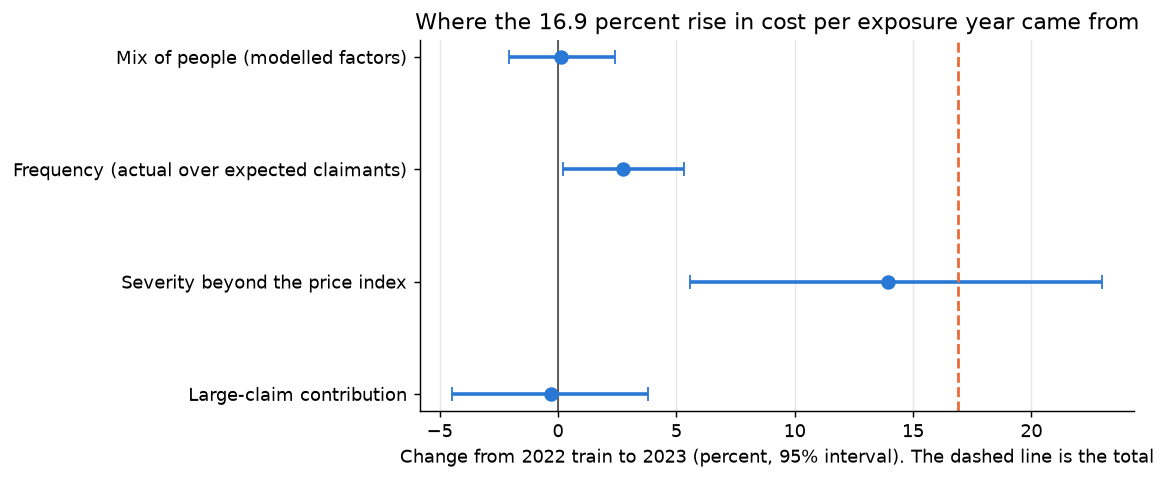

In [2]:
Image(filename=str(monitoring_summary.FIGURES_DIR / "gap_decomposition.png"))

**Decomposition of the gap.** Cost per exposure year is 16.9 percent higher in 2023. Severity beyond the price index is 13.9 percent (5.6 to 23.0) and frequency is 2.7 percent. Mix and large claims explain almost none of it.

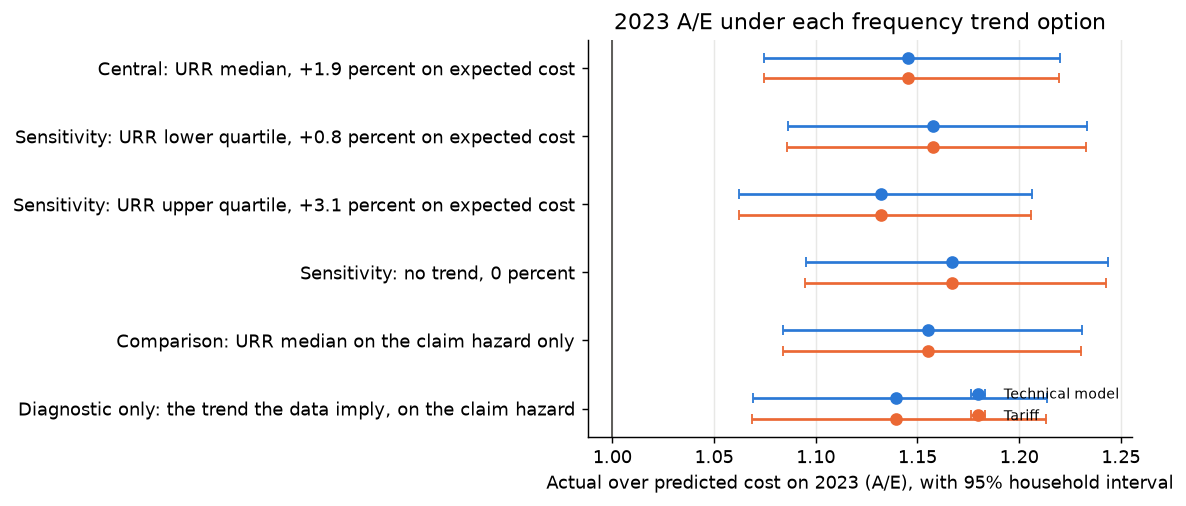

In [3]:
Image(filename=str(monitoring_summary.FIGURES_DIR / "ae_by_trend_option.png"))

**A/E by trend option.** The A/E of the technical model is 1.145 under the central 1.9 percent forecast, 1.158 at the low trend and 1.132 at the high trend. The tariff agrees to the second decimal.

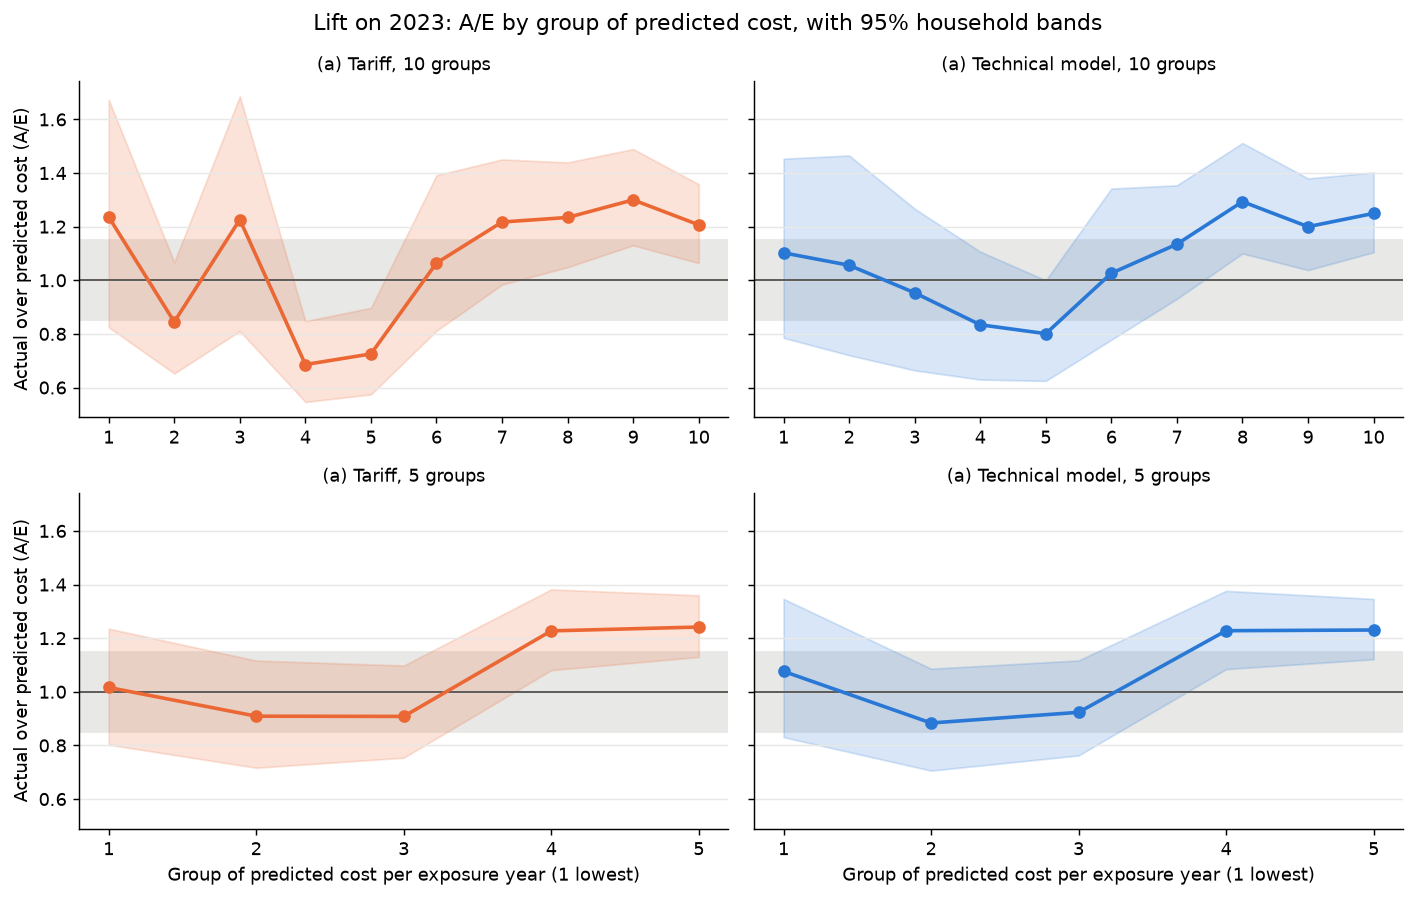

In [4]:
Image(filename=str(monitoring_summary.FIGURES_DIR / "lift_2023.png"))

**Lift on 2023 with household bands.** The ranking holds, with a Gini of 0.473 for the technical model and 0.468 for the tariff. The A/E of the top three deciles of the technical model is about 1.2 to 1.3, above the overall 1.145.

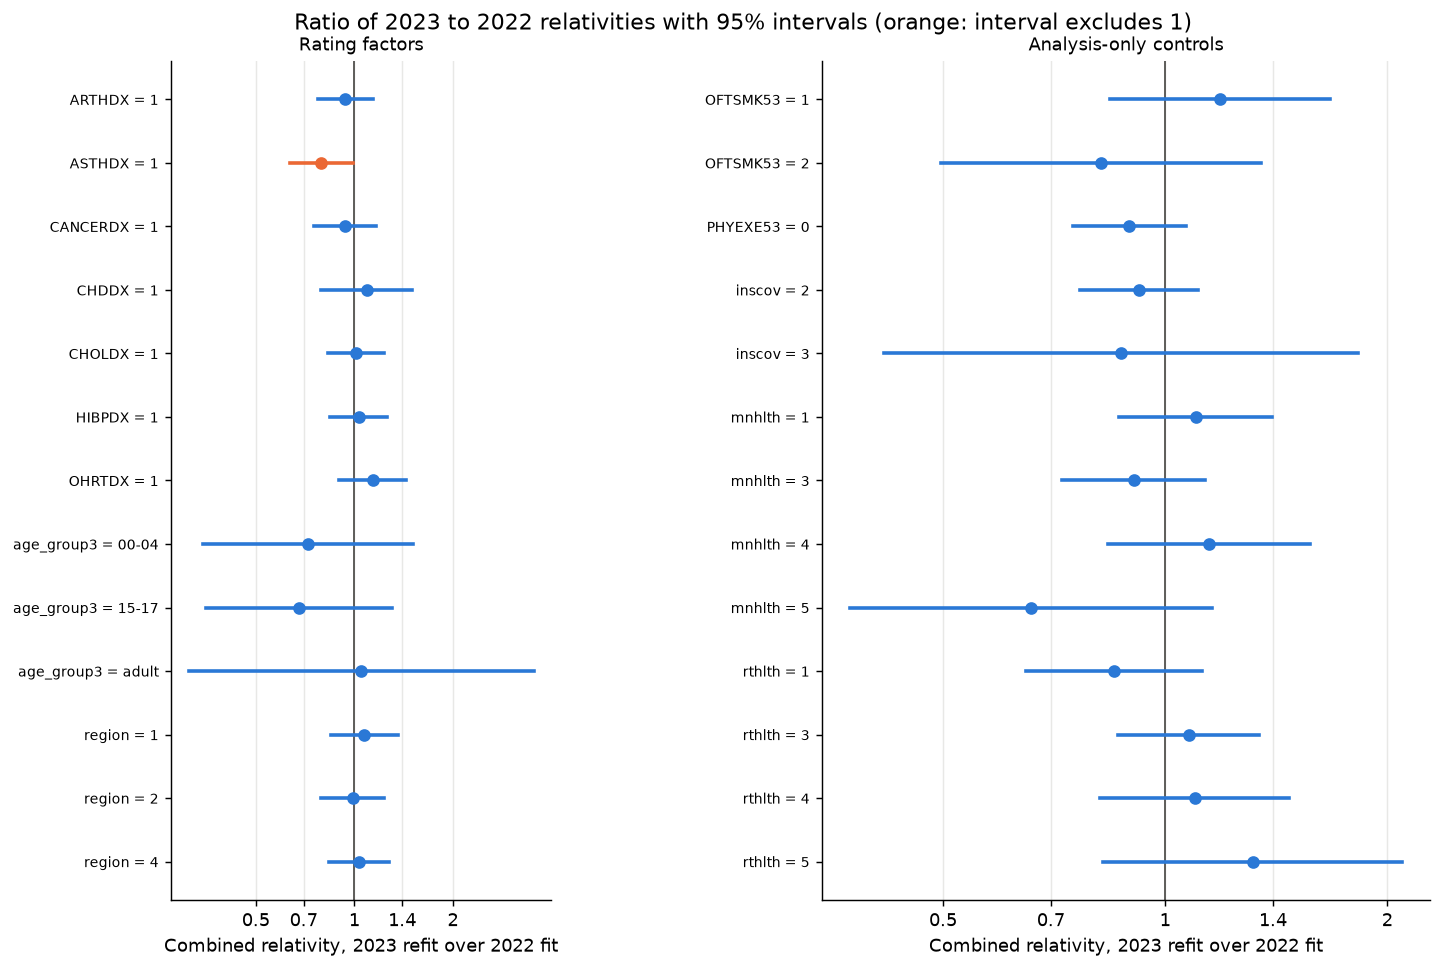

In [5]:
Image(filename=str(monitoring_summary.FIGURES_DIR / "relativity_stability_2023.png"))

**Relativity stability.** The ratio of the 2023 refit to the 2022 fit has an interval that contains 1 for all but one rating level (asthma), and the joint tests do not reject equal relativities.

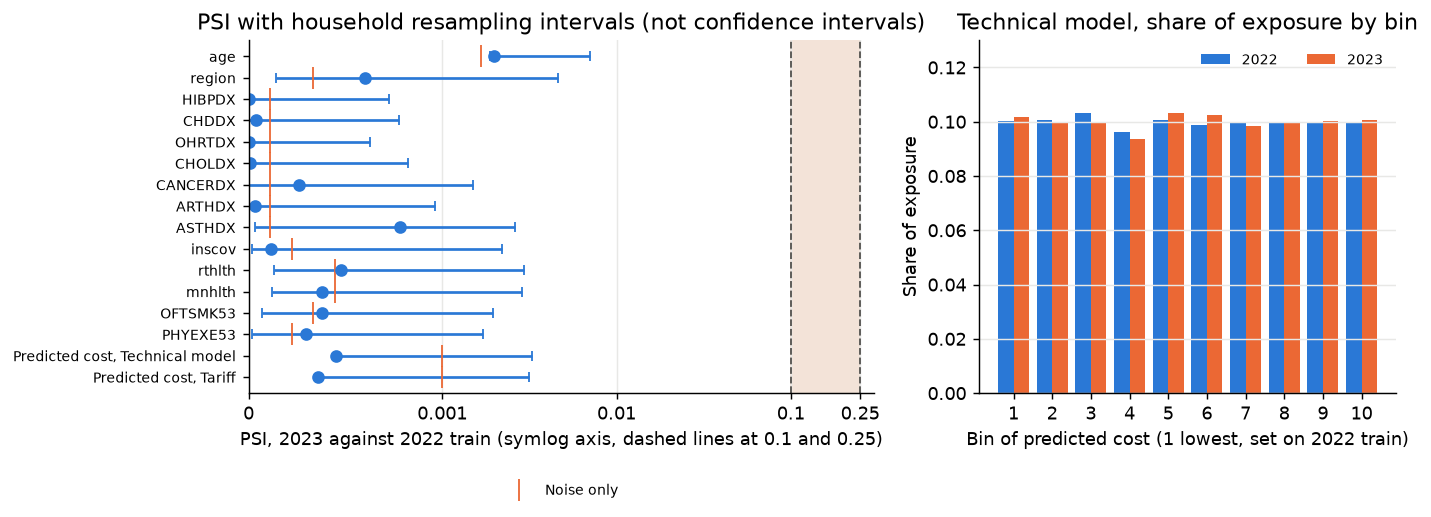

In [6]:
Image(filename=str(monitoring_summary.FIGURES_DIR / "drift_psi_2023.png"))

**PSI drift.** Every factor and the predicted cost have a PSI below 0.01, far below the 0.1 reading band. The mix did not move.

## Rebase decision

The recalibration rule reads the A/E, the stability tests, the count of levels beyond noise, the PSI and the Gini. On the 2023
evidence the structure, the mix and the ranking did not move and the A/E interval excludes 1, so the rule recommends a **rebase**
(a change of level) and not a refit of the relativities.

The user decided a rebase of **1.06** on the forecast cost, a credibility-weighted level change. The own 2023 experience implies a
rise of 14.5 percent, but its severity component is noisy (interval 5.6 to 23.0 percent). The CMS National Health Expenditure real
growth of 4.4 percent in 2023, against the 1.9 percent utilization trend already applied, implies about a further 2.5 percent. The
bounds are 1.025 and 1.145. The pooled refit of M6, with a year term, estimates the level directly and supersedes this rebase.

**Equation.** With $Z$ the weight on own experience, $(A/E)_{\text{own}}$ the A/E of 2023 and $g_{\text{ext}}$ the external level change
(the national real growth of 4.4 percent less the 1.9 percent trend already applied), the rebase is

$$\text{rebase} = 1 + Z \left( \left.\frac{A}{E}\right|_{\text{own}} - 1 \right) + (1 - Z)\, g_{\text{ext}}
= 1 + 0.3 \times 0.145 + 0.7 \times 0.025 \approx 1.06 .$$

The bounds are $Z = 0$, which gives $1.025$, and $Z = 1$, which gives $1.145$.

In [7]:
monitoring_summary.rebase_decision()

,own_level_change,credibility_of_own_experience,external_level_change,weighted_factor,decided_factor,lower_bound,upper_bound
0,0.145,0.300,0.025,1.061,1.060,1.025,1.145


## Limitations

- **US data.** The data are MEPS, a US survey, framed as UK private medical insurance. Costs, benefit design and the mix of people differ
  from a UK book, so the results show the method and not UK prices.
- **One out-of-time year.** The out-of-time test is a single year of 18,463 person-years with a heavy tail. The intervals are wide,
  and a year-to-year change in level cannot be separated from a lasting one.
- **Provisional large-claim load.** The load of 6.5 percent is from 2022 train and is not tuned to 2023. The 2023 excess is 6.2
  percent, so the load is not the source of the gap. It is re-estimated in M6.
- **The trend is an external assumption.** The 1.9 percent is a utilization trend from health insurers' rate filings, not a measured
  MEPS trend, and the severity part of the 2023 gap is noisy against national growth.
- **Conditions stand in for underwriting.** Diagnosed conditions are rating factors only because they are a stand-in for the
  health information that a UK insurer would collect at underwriting. The A/E by level shows a pattern for them that is worth watching.
- **Smoking.** Smoking is analysis-only and no discount or loading is applied.
- **The 2023 refit.** The refit on 2023 is for comparison only and its intervals treat two years of overlapping people as independent,
  so they are wider than they need to be.
- **The rebase.** The 1.06 is a judgement that weights one year of experience with an external level change. The M6 pooled refit
  with a year term supersedes it.
- **Rerun.** If M4 changes the chosen model, this notebook and its tables are rerun.